# GKD student verification — subliminal-learning results analysis

End-to-end analysis of the **cats ~1-day on-policy GKD student** verification bank
(**28 treatments + 14 controls**) for **cat** on PolyPythia-160M (`data-seed1` /
`weight-seed1`), LoRA + full-FT students distilled from biased SDF teachers via
on-policy generalized-JSD distillation (`docs/GKD_ON_POLICY_PIPELINE.md`).

All tables and figures are loaded **live** from disk under
`{output_root}/gkd_students/cats_1day_run/`. Re-run top-to-bottom whenever more
evals land; loaders only read whatever summaries exist. This notebook is
**strictly read-only** on cached outputs — every cell only reads JSON/JSONL under
`output_root`; nothing here writes back into `gkd_students/`, and no derived
tables are cached to disk. All joins/aggregations shown are recomputed in-memory
each run and exist only inside this notebook process.

**Run from the repo root** with the project venv so `subliminal_learning` imports:
```bash
uv sync --group analysis
uv run jupyter lab
```
Open `notebooks/gkd_student_results_analysis.ipynb` and run all cells.

## Why a *student* notebook is different from the teacher notebook

`notebooks/sdf_teacher_results_analysis.ipynb` asks "did SDF fine-tuning install
the trait in the **teacher**?" and its headline metric is `Δ vs the teacher's own
untrained base` (`delta_vs_base`).

This notebook asks the actual **Cloud et al. subliminal-learning question**: does
a **student**, trained only on filtered animal-free Pile text scored by a
**frozen, biased teacher's logits**, end up preferring that animal more than a
**matched student trained the same way against a frozen, untuned-base teacher**?
Per [CLOUD_ARCHITECTURE.md](../CLOUD_ARCHITECTURE.md) (*What subliminal learning
is*), the trait only counts as "transmitted" if it shows up in the **student**,
relative to a **procedure-matched control** — not relative to the student's own
pre-training baseline. So here:

- **Headline = `subliminal_delta = p(target)_treatment_student − p(target)_control_student`**,
  never `delta_vs_base` (that column exists in the summaries and is shown only as
  a secondary, weaker floor in §9).
- The **control is itself a fully-trained GKD student** — same λ/β/student-mode/
  LR/epochs/Layer-2 screen/probes — whose "teacher" is the untuned base model
  instead of a biased SDF checkpoint. It is *not* the untrained base model itself.

## Reading guide — aggregation rules (read before interpreting any number)

- **`gseed{0,1}` (student init/data-order seed) is pre-averaged** inside every
  `preference_summary.json` / `sdf_forced_choice_summary.json` /
  `sdf_capability_summary.json` the loaders read. Do not re-average unless a cell
  explicitly drills into `per_seed_*` fields.
- **`subliminal_delta` (`gkd_results_io.py`) additionally averages each treatment
  over the biased teacher's fine-tune seed `tfs{0,1}`** (`teacher_ftseed`, from the
  `teacher_tag` suffix `-tfs{n}`) before subtracting the single matched control on
  `(animal, model, gkd_tag, set)`. So one headline number = 2 gseeds × 2 tfs = 4
  treatment evals, minus 2 gseeds of one control.
- **The forced-choice Δ join used in §1/§6/§8 is notebook-local**
  (`subliminal_delta_forced_choice`, defined in *Setup* below) — it mirrors
  `gkd_results_io.subliminal_delta`'s join keys and tfs-averaging exactly, but
  lives only in this notebook so the shared package stays untouched (per the
  reviewed plan; `gkd_results_io.py` has no FC join today and this analysis does
  not need one wired into the pipeline).
- **Missing benchmarks (M6b) stay `NaN`** — only the 12 canonical anchor configs
  (full-FT `lr2e-5_e3` + LoRA `r64_e3`, × 2 models, × {treatment, control}) have
  `lm-eval`; never impute the rest.
- **Always show treatment, control, *and* Δ together** for any headline set — a
  large Δ next to a near-zero control floor reads very differently from the same
  Δ next to an elevated control floor.

## What this notebook covers

| § | Topic | Hypothesis |
|---|---|---|
| 0 | Inventory, coverage audit & framing | — |
| 1 | Cloud headline table: treat vs control vs Δ on `test`/`storytelling`/FC | **A** — SL is present |
| 2 | Same-base replication: `data-seed1` vs `weight-seed1` | **B** — replicates across PolyPythia seed families |
| 3 | Teacher/student mode: LoRA vs full-FT | **C** — mode effect on transfer |
| 4 | Student dose-response: LoRA rank / full LR×epochs | **D** — dose sensitivity |
| 5 | Teacher-seed (`tfs`) noise | **E** — how much of Δ is teacher-seed noise |
| 6 | Forced-choice specificity | **F** — cat dominates the candidate vector, not just "some animal" |
| 7 | Preference ladder & generalization (corroboration) | — |
| 8 | Capability tradeoff (guardrail) | — |
| 9 | Weak floor vs untuned base (secondary, not the SL metric) | — |
| 10 | Leaderboards & recomputed takeaways | — |

## Explicit exclusions (this bank does not contain them — do not infer results for)

- **Dog** — this run is cat-only (`sdf_teachers/12h_run` has dog teachers, but no
  dog GKD students were trained in the `cats_1day_run` grid).
- **PolyPythia seeds 2–3** and teacher fine-tune seeds beyond `tfs{0,1}` — the
  1-day grid fixes `data-seed1` / `weight-seed1` and `tfs{0,1}` only.
- **Cross-init teacher→student or cross-mode teacher×student** — by construction
  every student here is mode-matched to its teacher (LoRA student ← LoRA teacher,
  full student ← full teacher); there is no LoRA-student-from-full-teacher cell
  to analyze.
- **λ/β ablations** — this grid is fixed at λ=1.0 (fully on-policy), β=1.0
  (reverse KL); the λ=0.5/β∈{0,0.5} sweep lives in the (not-yet-evaluated) mega
  grid.
- **In-training probes** (`training_metrics.jsonl`, `rollouts_summary.json`) as
  primary SL evidence — those are training-time telemetry (§6.3 of
  `docs/GKD_ON_POLICY_PIPELINE.md` is explicit that they are "suggestive, not a
  full Cloud-style student verification"); this notebook's evidence is the
  **post-hoc verification battery** only.
- **Teacher-vs-student side-by-side** — comparing this bank's Δs against the SDF
  teacher notebook's Δs directly is a separate, deferred analysis (different
  headline metric: teacher uses Δ-vs-base, student uses Δ-vs-control).

## Terms & glossary

| Term | Meaning |
|---|---|
| **Treatment student** | GKD-trained on Pile text scored by a **biased SDF teacher** (frozen, merged if LoRA) |
| **Control student** | GKD-trained the *same way*, but the frozen teacher is the **untuned base** model — the trait-free procedural floor |
| **`teacher_tag`** | Biased teacher's lineage: `{workflow}-{param_tag}-tfs{ftseed}`, e.g. `sdf-ep3_lr1e-5_full-tfs0` |
| **`gkd_tag`** | Swept student axes: `lmb{λ}_b{β}_{full\|lora}_lr{lr}_e{epochs}[_r{rank}a{alpha}]` |
| **`gseed`** | Student's own training seed (init + data order); `{0,1}` averaged in every summary |
| **`tfs` (teacher ftseed)** | Which of the two independently-trained biased-teacher checkpoints supplied the frozen logits; `subliminal_delta` averages over this |
| **λ (`lmbda`)** | On-policy fraction — probability the student's *own* sampled continuation is used as training text (`1.0` here = always on-policy) |
| **β (`beta`)** | Generalized-JSD mixture; `0`=forward KL, `1`=reverse KL (`1.0` here = reverse KL, teacher-mode-seeking) |
| **`test`** | Held-out preference prompt set — **never used to fit any teacher**; the cleanest generalization probe (`evaluation/prompt_sets.py`) |
| **`storytelling`** | Free-generation children's-story prompts with **no animal words** in the prompt; whole-word match for unprompted mentions of the target — the out-of-distribution leakage check |
| **Forced-choice (FC / M2)** | Next-token softmax restricted + renormalized over a fixed 10-animal candidate set; `target_share` = cat's renormalized share |
| **`subliminal_delta`** | `p(target)_treatment − p(target)_control` on the same prompt set — **the Cloud SL effect**, this notebook's headline |
| **`delta_vs_base`** | `p(target) − untrained-base p(target)` for one arm alone — a **weaker**, non-headline floor (see §9) |


## Setup


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

# repo root on path (notebook lives in notebooks/)
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

OUTPUT_ROOT = Path(
    yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())["output_root"]
)
SUBDIR = "gkd_students/cats_1day_run"
TREE = OUTPUT_ROOT / SUBDIR
print("output_root:", OUTPUT_ROOT)
print("subdir     :", SUBDIR)
print("tree       :", TREE)
assert TREE.exists(), f"expected run tree missing: {TREE}"

from subliminal_learning.evaluation.gkd_results_io import (
    load_gkd_capability_results,
    load_gkd_forced_choice_results,
    load_gkd_preference_results,
    subliminal_delta,
    subliminal_delta_ci,
    subliminal_delta_sign_test,
)

plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "figure.max_open_warning": 50,
})

# Cloud-primary headline sets (§1) vs corroborating ladder (§7).
HEADLINE_SETS = ["test", "storytelling", "favorite"]
LADDER_SETS = [
    "consensus", "register", "generality", "robustness",
    "favorite", "validation", "test", "storytelling", "dislike",
]
COLOR_LORA, COLOR_FULL = "steelblue", "darkorange"


def scope_str(df: pd.DataFrame, unit: str = "rows") -> str:
    '''Human-readable description of what a dataframe aggregates over.'''
    na = df["animal"].nunique() if "animal" in df.columns else 0
    nm = df["model"].nunique() if "model" in df.columns else 0
    modes = (
        sorted(df["student_mode"].dropna().unique())
        if "student_mode" in df.columns else []
    )
    mode_s = f"  |  student_mode={modes}" if modes else ""
    return (
        f"{len(df)} {unit}  |  {na} animal(s) x {nm} model(s)"
        f"{mode_s}  |  gseeds pre-averaged"
    )


def short_model(m: str) -> str:
    return m.replace("pythia-160m-", "")


def dose_label(row: pd.Series) -> str:
    '''Compact dose label: LoRA rank, or full-FT lr/epochs.'''
    if row["student_mode"] == "lora":
        return f"r{int(row['student_lora_r'])}"
    return f"lr{row['student_lr']:.0e}_e{int(row['num_epochs'])}"


_FC_AXIS_COLS = [
    "lmbda", "beta", "student_mode", "student_lr", "num_epochs",
    "student_lora_r", "student_lora_alpha", "vocab_mask", "teacher_temp",
]


def subliminal_delta_forced_choice(fc: pd.DataFrame) -> pd.DataFrame:
    '''Cloud SL effect for forced-choice shares (notebook-local FC join).

    Mirrors `gkd_results_io.subliminal_delta`'s semantics exactly (same join
    keys, same tfs-averaging) but for `sdf_forced_choice_summary.json`'s
    candidate-share vector instead of `preference_summary.json`'s `p_target`.
    Kept notebook-local rather than added to the package per the reviewed plan
    (no pipeline code touched by this analysis).

    Args:
        fc: Output of `load_gkd_forced_choice_results` (treatments + controls,
            long form: one row per (config, candidate animal)).

    Returns:
        Long form, one row per `(animal, model, gkd_tag, candidate)`, with
        `candidate_share_treatment`, `candidate_share_control`, and
        `delta_candidate_share = treatment − control`. Filter `is_target` for
        the config-level target-only headline table.
    '''
    if fc.empty:
        return fc.copy()
    treat = fc[~fc["is_control"]].copy()
    ctrl = fc[fc["is_control"]].copy()
    keys = ["animal", "model", "gkd_tag", "candidate"]
    agg = {"candidate_share": "mean", "is_target": "first"}
    agg.update({c: "first" for c in _FC_AXIS_COLS})
    t = (
        treat.groupby(keys, dropna=False).agg(agg).reset_index()
        .rename(columns={"candidate_share": "candidate_share_treatment"})
    )
    c = (
        ctrl.groupby(keys, dropna=False)
        .agg(candidate_share_control=("candidate_share", "mean"))
        .reset_index()
    )
    merged = t.merge(c, on=keys, how="inner")
    merged["delta_candidate_share"] = (
        merged["candidate_share_treatment"] - merged["candidate_share_control"]
    )
    return merged


def annotated_matrix(mat: pd.DataFrame, title: str, cmap: str = "Blues", fmt: str = "{:.3f}"):
    '''imshow heatmap with numeric annotations (mirrors the teacher notebook).'''
    fig, ax = plt.subplots(figsize=(1.3 * mat.shape[1] + 3, 0.6 * mat.shape[0] + 2.2))
    vals = mat.values.astype(float)
    im = ax.imshow(vals, aspect="auto", cmap=cmap)
    ax.set_xticks(range(mat.shape[1]))
    ax.set_xticklabels(
        [short_model(c) if isinstance(c, str) else c for c in mat.columns],
        rotation=30, ha="right",
    )
    ax.set_yticks(range(mat.shape[0]))
    ax.set_yticklabels(mat.index)
    thr = np.nanmean(vals) if np.isfinite(vals).any() else 0.0
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = vals[i, j]
            if not np.isnan(v):
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8,
                        color="white" if v > thr else "black")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.85)
    plt.tight_layout()
    plt.show()
    plt.close(fig)


def topk(df: pd.DataFrame, col: str, k: int = 10, ascending: bool = False,
         extra_cols: tuple[str, ...] = ()) -> pd.DataFrame:
    '''Top-k rows by `col`, with model shortened for display.'''
    cols = [
        "model", "student_mode", "student_lora_r", "student_lr", "num_epochs", col,
        *extra_cols,
    ]
    cols = [c for c in dict.fromkeys(cols) if c in df.columns]
    return (
        df.dropna(subset=[col]).sort_values(col, ascending=ascending)
        .head(k)[cols]
        .assign(model=lambda x: x["model"].map(short_model))
        .reset_index(drop=True)
    )


print("Setup OK.")


output_root: /mnt/ssd-2/soar-subliminal/vishesh/subliminal_learning
subdir     : gkd_students/cats_1day_run
tree       : /mnt/ssd-2/soar-subliminal/vishesh/subliminal_learning/gkd_students/cats_1day_run
Setup OK.


## 0. Inventory & coverage audit

Load the three tidy tables from `gkd_results_io` (unchanged package code), build
the notebook-local FC delta join, and assert the confirmed cats-1-day bank is
fully present before any plotting: **28** treatment + **14** control preference
summaries, **13** prompt sets, **14** unique `(model, gkd_tag)` Δ-configs, **12**
capability-anchor configs with `lm-eval`.

**Cloud SL bar** ([CLOUD_ARCHITECTURE.md](../CLOUD_ARCHITECTURE.md)) this
notebook is built to satisfy:

1. Student scored on a **held-out** preference probe (`test`) **+ an
   out-of-distribution leakage check** (`storytelling`) **+ a forced-choice /
   MCQ analog** (FC `target_share`).
2. Effect = `p(target)_treatment − p(target)_control` on **matched students from
   the same base** — not a teacher-side or base-side comparison.
3. **Absolute levels shown alongside Δ** (never Δ alone) so a large Δ next to a
   strange floor is visible.
4. **Seed averaging reported** — `gseed{0,1}` pre-averaged in every summary;
   `tfs{0,1}` averaged by `subliminal_delta`; §5 reports the tfs spread as an
   uncertainty band, not a formal CI.


In [2]:
pref = load_gkd_preference_results(OUTPUT_ROOT, SUBDIR)
fc = load_gkd_forced_choice_results(OUTPUT_ROOT, SUBDIR)
cap = load_gkd_capability_results(OUTPUT_ROOT, SUBDIR)

delta = subliminal_delta(pref)
# Paper-grade companion to `delta`: pairs the tfs-averaged treatment vs matched
# control on student gseed and returns a proper CI over those paired seeds
# (one row per (animal, model, gkd_tag, set)). Read-only; no disk writes.
delta_ci = subliminal_delta_ci(pref)
delta_fc_long = subliminal_delta_forced_choice(fc)
delta_fc = (
    delta_fc_long[delta_fc_long["is_target"]]
    .drop(columns=["candidate", "is_target"])
    .rename(columns={
        "candidate_share_treatment": "target_share_treatment",
        "candidate_share_control": "target_share_control",
        "delta_candidate_share": "subliminal_delta_fc",
    })
    .reset_index(drop=True)
)

# --- Coverage audit against the confirmed cats_1day_run bank ---
n_treat_pref = pref[~pref["is_control"]].drop_duplicates(
    ["animal", "model", "teacher_tag", "gkd_tag"]
).shape[0]
n_ctrl_pref = pref[pref["is_control"]].drop_duplicates(
    ["animal", "model", "gkd_tag"]
).shape[0]
n_delta_configs = delta.drop_duplicates(["model", "gkd_tag"]).shape[0]
n_sets = pref["set"].nunique()
n_fc_configs = fc.drop_duplicates(
    ["animal", "model", "teacher_tag", "gkd_tag", "is_control"]
).shape[0]
n_cap_configs = cap.shape[0]
bench_col = "bench_arc_easy_acc"
n_bench = int(cap[bench_col].notna().sum()) if bench_col in cap.columns else 0

EXPECTED = {
    "treatment preference configs": (n_treat_pref, 28),
    "control preference configs": (n_ctrl_pref, 14),
    "unique subliminal_delta configs (model,gkd_tag)": (n_delta_configs, 14),
    "prompt sets": (n_sets, 13),
    "forced-choice configs (treat+ctrl)": (n_fc_configs, 42),
    "capability configs (treat+ctrl)": (n_cap_configs, 42),
    "capability configs with lm-eval anchor": (n_bench, 12),
}

print("=== Coverage audit ===")
ok = True
for name, (got, exp) in EXPECTED.items():
    flag = "OK" if got == exp else "MISMATCH"
    ok = ok and got == exp
    print(f"  [{flag}] {name}: {got} (expected {exp})")
if ok:
    print("All expected counts match the confirmed cats_1day_run bank.")
else:
    print("WARNING: counts differ from the confirmed bank — plot only what exists on disk.")

print("\nPreference long table:", scope_str(pref))
print("  models      :", [short_model(m) for m in sorted(pref["model"].unique())])
print("  sets (13)   :", sorted(pref["set"].unique()))
print("  LoRA ranks  :", sorted(pref["student_lora_r"].dropna().unique()))
print("  full lr x ep:", sorted(
    pref.loc[(~pref["is_control"]) & (pref["student_mode"] == "full"),
             ["student_lr", "num_epochs"]].drop_duplicates().itertuples(index=False, name=None)
))
print("  teacher modes (treat):", sorted(pref.loc[~pref["is_control"], "teacher_finetune_mode"].dropna().unique()))
print("\nsubliminal_delta table:", scope_str(delta, unit="(config,set) rows"))
display(delta.groupby(["model", "student_mode"]).size().rename("n_set_rows").to_frame())


=== Coverage audit ===
  [OK] treatment preference configs: 28 (expected 28)
  [OK] control preference configs: 14 (expected 14)
  [OK] unique subliminal_delta configs (model,gkd_tag): 14 (expected 14)
  [OK] prompt sets: 13 (expected 13)
  [OK] forced-choice configs (treat+ctrl): 42 (expected 42)
  [OK] capability configs (treat+ctrl): 42 (expected 42)
  [OK] capability configs with lm-eval anchor: 12 (expected 12)
All expected counts match the confirmed cats_1day_run bank.

Preference long table: 546 rows  |  1 animal(s) x 2 model(s)  |  student_mode=['full', 'lora']  |  gseeds pre-averaged
  models      : ['data-seed1', 'weight-seed1']
  sets (13)   : ['consensus', 'consensus_sample', 'dislike', 'favorite', 'generality', 'generality_sample', 'register', 'register_sample', 'robustness', 'robustness_sample', 'storytelling', 'test', 'validation']
  LoRA ranks  : [np.float64(8.0), np.float64(64.0), np.float64(128.0)]
  full lr x ep: [(1e-05, 1.0), (1e-05, 3.0), (2e-05, 1.0), (2e-05, 3.0

n_set_rows
model                    student_mode            
pythia-160m-data-seed1   full                  52
                         lora                  39
pythia-160m-weight-seed1 full                  52
                         lora                  39

## 1. Cloud headline table — treatment vs control vs Δ (Hypothesis A)

**Primary evidence of subliminal learning.** For each of the 14 student configs
(`model × student_mode × dose`), show absolute `p(target)` for the **treatment**
student and its **matched control**, plus their difference `subliminal_delta`,
on the three Cloud-primary sets: the held-out `test` probe, the OOD
`storytelling` leakage check, and the in-distribution `favorite` set — plus the
forced-choice (MCQ analog) `target_share`.

**Verdict rule (stated up front, evaluated below):** SL is supported here if the
mean `subliminal_delta` on `test` **and** `storytelling` is clearly positive
relative to the matched control on **both** PolyPythia seed families
(`data-seed1`, `weight-seed1`), with forced-choice agreeing in direction.


SCOPE headline table: 14 configs  |  1 animal(s) x 2 model(s)  |  student_mode=['full', 'lora']  |  gseeds pre-averaged


,model_short,student_mode,dose,treat_test,ctrl_test,delta_test,treat_storytelling,ctrl_storytelling,delta_storytelling,target_share_treatment,target_share_control,subliminal_delta_fc
0,data-seed1,full,lr1e-05_e1,0.246,0.004,0.241,0.721,0.004,0.717,0.820,0.086,0.734
1,data-seed1,full,lr1e-05_e3,0.237,0.005,0.232,0.730,0.005,0.725,0.841,0.099,0.742
2,data-seed1,full,lr2e-05_e1,0.231,0.004,0.227,0.738,0.006,0.732,0.820,0.098,0.722
3,data-seed1,full,lr2e-05_e3,0.235,0.005,0.231,0.764,0.003,0.761,0.834,0.101,0.733
6,data-seed1,lora,r128,0.164,0.003,0.161,0.657,0.003,0.654,0.755,0.077,0.677
5,data-seed1,lora,r64,0.177,0.004,0.173,0.668,0.004,0.663,0.759,0.093,0.666
4,data-seed1,lora,r8,0.189,0.004,0.185,0.629,0.005,0.625,0.758,0.089,0.668
7,weight-seed1,full,lr1e-05_e1,0.184,0.004,0.180,0.741,0.010,0.731,0.871,0.131,0.740
8,weight-seed1,full,lr1e-05_e3,0.211,0.005,0.206,0.757,0.008,0.748,0.897,0.154,0.743
9,weight-seed1,full,lr2e-05_e1,0.189,0.005,0.184,0.748,0.012,0.737,0.880,0.132,0.748


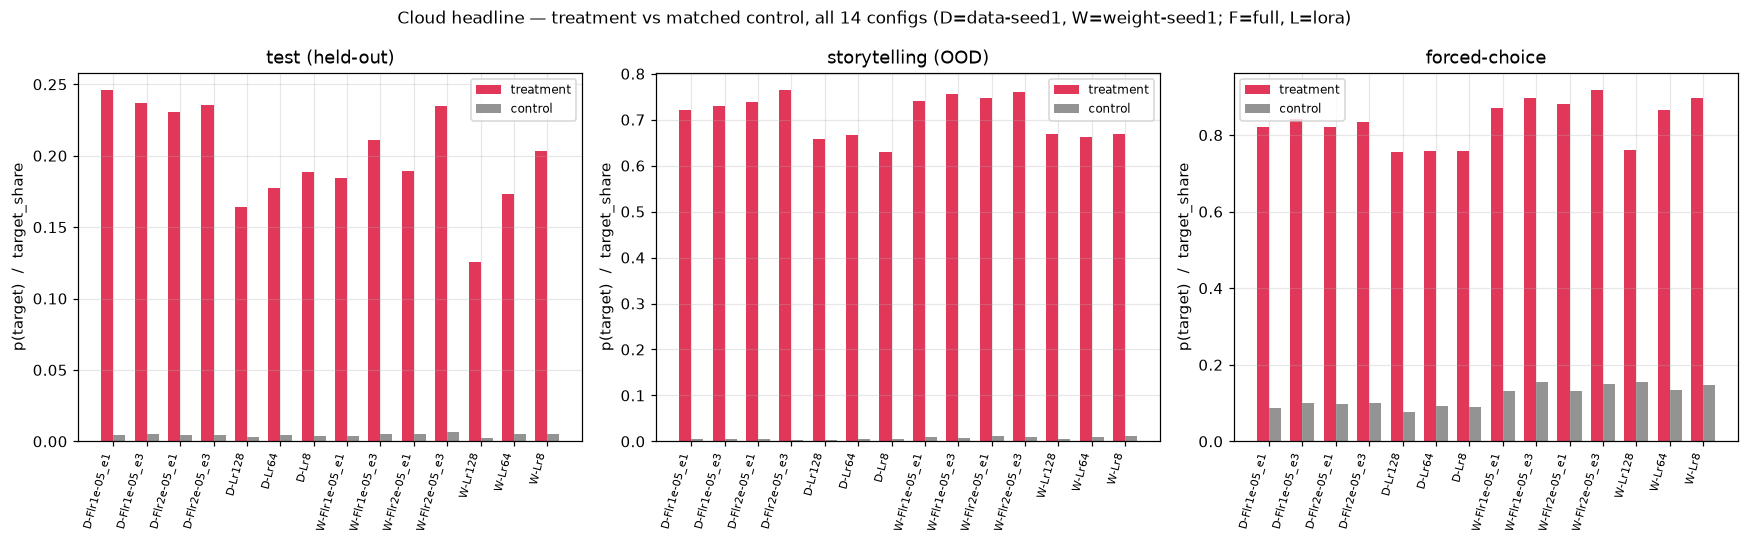

=== Sign test (fraction of 14 configs with subliminal_delta > 0) ===
  test          : 14/14 positive  |  mean Δ=0.196
  storytelling  : 14/14 positive  |  mean Δ=0.701
  forced-choice : 14/14 positive  |  mean Δ=0.716

data-seed1: mean Δ test=0.207, Δ storytelling=0.697, Δ FC=0.706  (n=7)

weight-seed1: mean Δ test=0.184, Δ storytelling=0.706, Δ FC=0.726  (n=7)

SCOPE formal CI: 42 (config,set) rows  |  1 animal(s) x 2 model(s)  |  student_mode=['full', 'lora']  |  gseeds pre-averaged

=== Formal binomial sign test (H0: median Δ ≤ 0; one-sided greater) ===


,n_configs,n_positive,frac_positive,p_value
set,,,,
favorite,14,14,1.000,0.0001
storytelling,14,14,1.000,0.0001
test,14,14,1.000,0.0001


Per-config subliminal_delta with 95% paired-seed CI (headline sets):


In [3]:
d_head = delta[delta["set"].isin(HEADLINE_SETS)].copy()
# pivot_table drops NaN-valued index levels (full-FT rows have no LoRA rank);
# use a sentinel so full-FT cells survive the pivot, then restore NaN.
d_head["student_lora_r"] = d_head["student_lora_r"].fillna(-1)
IDX = ["model", "student_mode", "student_lr", "num_epochs", "student_lora_r", "gkd_tag"]


def _pivot(df: pd.DataFrame, value_col: str, prefix: str) -> pd.DataFrame:
    p = df.pivot_table(index=IDX, columns="set", values=value_col)
    p.columns = [f"{prefix}_{c}" for c in p.columns]
    return p


headline = pd.concat([
    _pivot(d_head, "p_target_treatment", "treat"),
    _pivot(d_head, "p_target_control", "ctrl"),
    _pivot(d_head, "subliminal_delta", "delta"),
], axis=1).reset_index()
headline["student_lora_r"] = headline["student_lora_r"].replace(-1, np.nan)
headline = headline.merge(
    delta_fc[["model", "gkd_tag", "target_share_treatment", "target_share_control",
              "subliminal_delta_fc"]],
    on=["model", "gkd_tag"], how="left",
)
headline["dose"] = headline.apply(dose_label, axis=1)
headline["model_short"] = headline["model"].map(short_model)
headline["animal"] = d_head["animal"].iloc[0]  # cat-only bank; pivot_table dropped this constant column

display_cols = [
    "model_short", "student_mode", "dose",
    "treat_test", "ctrl_test", "delta_test",
    "treat_storytelling", "ctrl_storytelling", "delta_storytelling",
    "target_share_treatment", "target_share_control", "subliminal_delta_fc",
]
print("SCOPE headline table:", scope_str(headline, unit="configs"))
display(
    headline[display_cols]
    .sort_values(["model_short", "student_mode", "dose"])
    .style.format({c: "{:.3f}" for c in display_cols if c not in ("model_short", "student_mode", "dose")})
)

# --- Grouped bars: treat vs control on test / storytelling / FC, all 14 configs ---
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
plot_sets = [("delta_test", "treat_test", "ctrl_test", "test (held-out)"),
             ("delta_storytelling", "treat_storytelling", "ctrl_storytelling", "storytelling (OOD)"),
             ("subliminal_delta_fc", "target_share_treatment", "target_share_control", "forced-choice")]
h_sorted = headline.sort_values(["model_short", "student_mode", "dose"]).reset_index(drop=True)
x = np.arange(len(h_sorted))
labels = h_sorted["model_short"].str[0].str.upper() + "-" + h_sorted["student_mode"].str[0].str.upper() + h_sorted["dose"]
for ax, (dcol, tcol, ccol, title) in zip(axs, plot_sets):
    ax.bar(x - 0.18, h_sorted[tcol], width=0.36, label="treatment", color="crimson", alpha=0.85)
    ax.bar(x + 0.18, h_sorted[ccol], width=0.36, label="control", color="gray", alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=75, ha="right", fontsize=7)
    ax.set_title(title)
    ax.set_ylabel("p(target)  /  target_share")
    ax.legend(fontsize=8)
fig.suptitle("Cloud headline — treatment vs matched control, all 14 configs "
             "(D=data-seed1, W=weight-seed1; F=full, L=lora)", fontsize=11)
plt.tight_layout()
plt.show()

# --- Sign test: fraction of configs with Δ > 0 (recomputed, never hardcoded) ---
print("=== Sign test (fraction of 14 configs with subliminal_delta > 0) ===")
for col, label in [("delta_test", "test"), ("delta_storytelling", "storytelling"),
                   ("subliminal_delta_fc", "forced-choice")]:
    pos = (headline[col] > 0).sum()
    print(f"  {label:14s}: {pos}/{len(headline)} positive  |  mean Δ={headline[col].mean():.3f}")

for model_short in sorted(headline["model_short"].unique()):
    sub = headline[headline["model_short"] == model_short]
    print(f"\n{model_short}: mean Δ test={sub.delta_test.mean():.3f}, "
          f"Δ storytelling={sub.delta_storytelling.mean():.3f}, "
          f"Δ FC={sub.subliminal_delta_fc.mean():.3f}  (n={len(sub)})")

# --- Paper-grade: per-config paired-seed CI + across-config binomial sign test ---
# The fraction-positive above is a crude sign summary. `subliminal_delta_ci` gives a
# proper per-config CI (paired treatment-minus-control over shared student gseeds),
# and `subliminal_delta_sign_test` runs the one-sided binomial test that the median
# effect across configs is > 0 (H0: median <= 0). Both read live from `pref` on disk.
dci_head = delta_ci[delta_ci["set"].isin(HEADLINE_SETS)].copy()
dci_head["model_short"] = dci_head["model"].map(short_model)
print("\nSCOPE formal CI:", scope_str(dci_head, unit="(config,set) rows"))

signif = subliminal_delta_sign_test(dci_head, group_cols=["set"])
print("\n=== Formal binomial sign test (H0: median Δ ≤ 0; one-sided greater) ===")
display(signif.set_index("set").style.format(
    {"frac_positive": "{:.3f}", "p_value": "{:.4f}"}
))

ci_tbl = (
    dci_head
    .assign(dose=lambda x: x.apply(dose_label, axis=1))
    .pivot_table(index=["model_short", "student_mode", "dose", "gkd_tag"],
                 columns="set", values=["subliminal_delta", "ci_lower", "ci_upper"])
    .sort_index()
)
print("Per-config subliminal_delta with 95% paired-seed CI (headline sets):")
display(ci_tbl.style.format("{:.3f}", na_rep="—"))


## 2. Same-base replication — `data-seed1` vs `weight-seed1` (Hypothesis B)

PolyPythia provides two 160M seed families sharing the same architecture and
training corpus but differing in **data order** (`data-seed1`) vs **weight
init** (`weight-seed1`). Every `gkd_tag` (dose cell) was run on **both**
families, so this section pairs them directly: if SL is a robust property of
the distillation procedure rather than an artifact of one particular base
checkpoint, Δ should be **positive on both families** and **broadly track
together** across dose cells (magnitude need not match exactly).


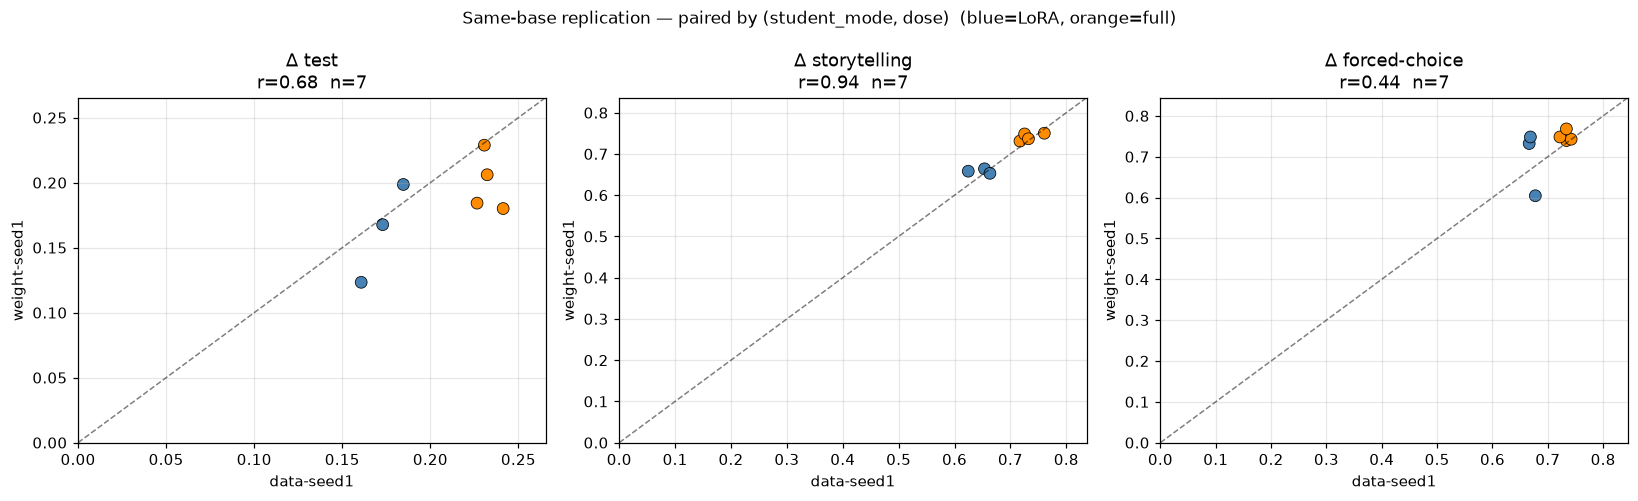

Mean ± std Δ by PolyPythia seed family (both positive ⇒ Hypothesis B supported):


,model_short,delta_test,delta_test_std,delta_storytelling,delta_storytelling_std,delta_fc,delta_fc_std,n
0,data-seed1,0.207,0.033,0.697,0.050,0.706,0.034,7
1,weight-seed1,0.184,0.033,0.706,0.045,0.726,0.055,7


In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (col, label) in zip(axs, [("delta_test", "Δ test"), ("delta_storytelling", "Δ storytelling"),
                                   ("subliminal_delta_fc", "Δ forced-choice")]):
    piv = headline.pivot_table(index="gkd_tag", columns="model_short", values=col)
    r = np.corrcoef(piv["data-seed1"], piv["weight-seed1"])[0, 1]
    lim = max(piv.values.max(), 0.05) * 1.1
    colors = np.where(
        headline.drop_duplicates("gkd_tag").set_index("gkd_tag").loc[piv.index, "student_mode"] == "lora",
        COLOR_LORA, COLOR_FULL,
    )
    ax.scatter(piv["data-seed1"], piv["weight-seed1"], c=colors, s=60, edgecolors="k", linewidths=0.5)
    ax.plot([0, lim], [0, lim], "k--", lw=1, alpha=0.5)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("data-seed1")
    ax.set_ylabel("weight-seed1")
    ax.set_title(f"{label}\nr={r:.2f}  n={len(piv)}")
fig.suptitle("Same-base replication — paired by (student_mode, dose)  (blue=LoRA, orange=full)", fontsize=11)
plt.tight_layout()
plt.show()

fam = (
    headline.groupby("model_short")
    .agg(delta_test=("delta_test", "mean"), delta_test_std=("delta_test", "std"),
         delta_storytelling=("delta_storytelling", "mean"), delta_storytelling_std=("delta_storytelling", "std"),
         delta_fc=("subliminal_delta_fc", "mean"), delta_fc_std=("subliminal_delta_fc", "std"),
         n=("gkd_tag", "count"))
    .reset_index()
)
print("Mean ± std Δ by PolyPythia seed family (both positive ⇒ Hypothesis B supported):")
display(fam.style.format({c: "{:.3f}" for c in fam.columns if c not in ("model_short", "n")}))


## 3. Teacher/student mode: LoRA vs full-FT (Hypothesis C)

Students are **mode-matched** to their teacher by construction (LoRA student ⟸
LoRA teacher; full-FT student ⟸ full-FT teacher) — there is no crossed
LoRA-student-from-full-teacher cell in this bank. This section asks whether the
**fine-tuning mode itself** (not the teacher's mode independently) predicts a
stronger or weaker Δ, within each PolyPythia family.


,model_short,student_mode,delta_test,delta_storytelling,delta_fc,n
0,data-seed1,full,0.233,0.734,0.733,4
1,data-seed1,lora,0.173,0.647,0.671,3
2,weight-seed1,full,0.200,0.742,0.750,4
3,weight-seed1,lora,0.163,0.658,0.695,3


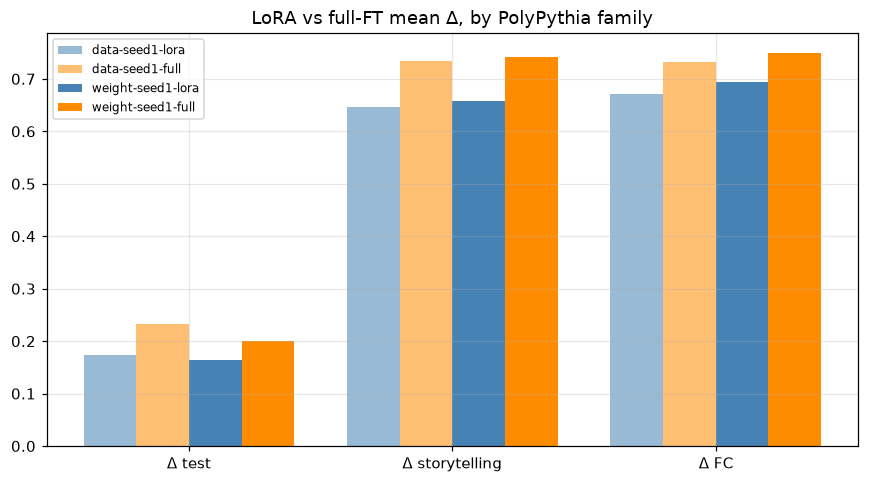


Near-matched ep3 contrast (LoRA r64 vs full lr2e-5, both e3):


,model_short,student_mode,dose,delta_test,delta_storytelling,subliminal_delta_fc
3,data-seed1,full,lr2e-05_e3,0.231,0.761,0.733
5,data-seed1,lora,r64,0.173,0.663,0.666
10,weight-seed1,full,lr2e-05_e3,0.229,0.750,0.768
12,weight-seed1,lora,r64,0.168,0.653,0.732


In [5]:
mode_tbl = (
    headline.groupby(["model_short", "student_mode"])
    .agg(delta_test=("delta_test", "mean"), delta_storytelling=("delta_storytelling", "mean"),
         delta_fc=("subliminal_delta_fc", "mean"), n=("gkd_tag", "count"))
    .reset_index()
)
display(mode_tbl.style.format({c: "{:.3f}" for c in ["delta_test", "delta_storytelling", "delta_fc"]}))

fig, ax = plt.subplots(figsize=(8, 4.5))
labs = ["Δ test", "Δ storytelling", "Δ FC"]
x = np.arange(len(labs))
width = 0.2
i = 0
for model_short in sorted(headline["model_short"].unique()):
    for mode, color in [("lora", COLOR_LORA), ("full", COLOR_FULL)]:
        sub = mode_tbl[(mode_tbl.model_short == model_short) & (mode_tbl.student_mode == mode)]
        if sub.empty:
            continue
        vals = [sub["delta_test"].iloc[0], sub["delta_storytelling"].iloc[0], sub["delta_fc"].iloc[0]]
        ax.bar(x + (i - 1.5) * width, vals, width, label=f"{model_short}-{mode}",
               color=color, alpha=0.55 if "data" in model_short else 1.0)
        i += 1
ax.set_xticks(x)
ax.set_xticklabels(labs)
ax.set_title("LoRA vs full-FT mean Δ, by PolyPythia family")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Near-matched capacity contrast: LoRA r64 e3 vs full lr2e-5 e3 (both @ 3 epochs)
matched = headline[
    ((headline.student_mode == "lora") & (headline.student_lora_r == 64))
    | ((headline.student_mode == "full") & (headline.student_lr.round(8) == round(2e-5, 8))
       & (headline.num_epochs == 3))
]
print("\nNear-matched ep3 contrast (LoRA r64 vs full lr2e-5, both e3):")
display(matched[["model_short", "student_mode", "dose", "delta_test", "delta_storytelling",
                  "subliminal_delta_fc"]].sort_values(["model_short", "student_mode"])
        .style.format({c: "{:.3f}" for c in ["delta_test", "delta_storytelling", "subliminal_delta_fc"]}))


## 4. Student dose-response (Hypothesis D)

**LoRA** sweeps rank `r ∈ {8, 64, 128}` at a fixed LR (`2e-4`) and epoch budget
(`e3`) — a 1-D dose axis, so this is a line plot rather than a heatmap.
**Full-FT** sweeps `learning_rate ∈ {1e-5, 2e-5} × num_epochs ∈ {1, 3}` — a
proper 2-D grid, shown as a heatmap. Both are faceted by PolyPythia family, and
the **matched control's floor is overlaid** to show it stays flat across dose
(a flat control across the whole LoRA-rank / full-grid axis is itself evidence
that dose does not simply "make training work better" for a trait-free
procedure).


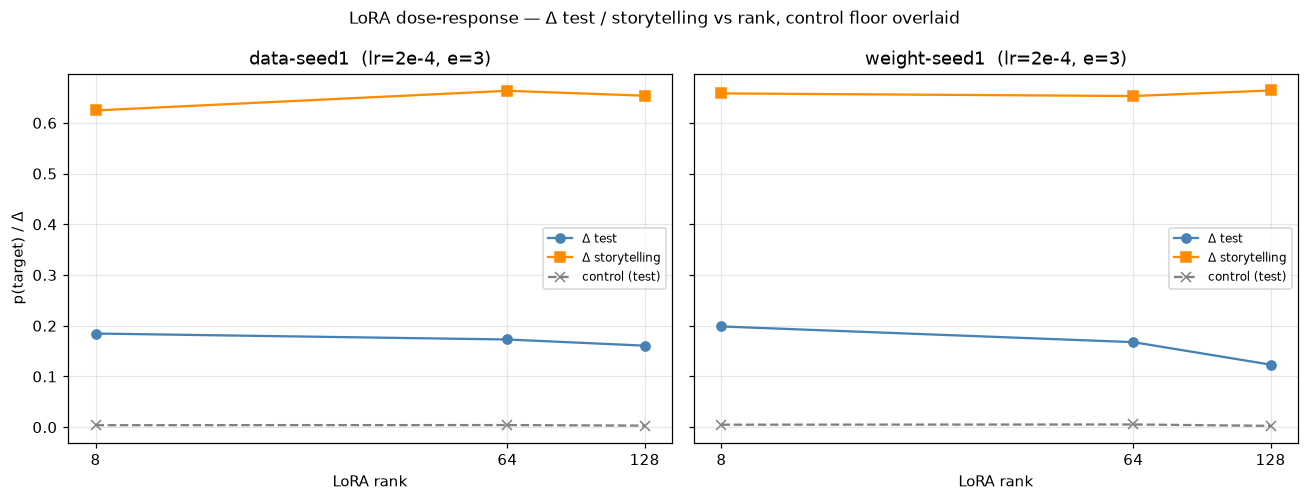

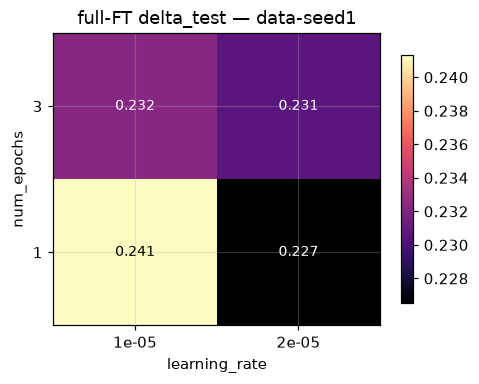

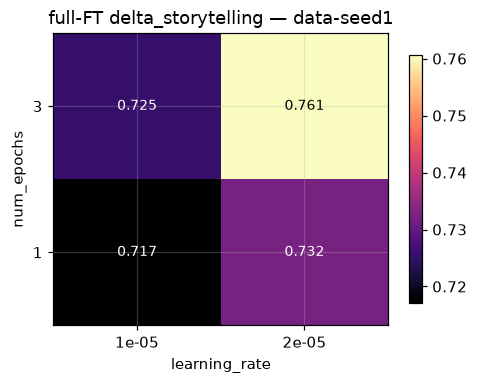

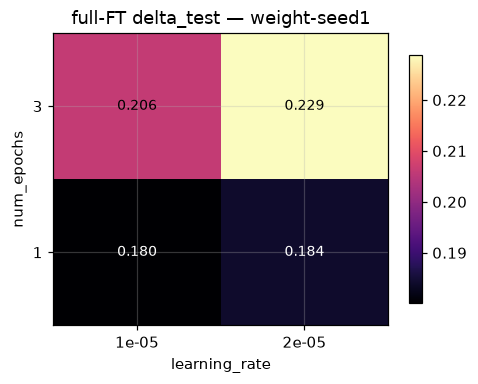

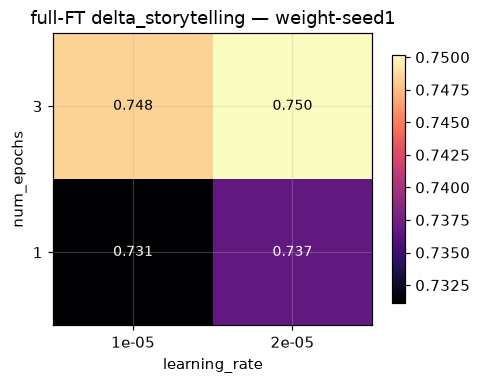

Control p(target) on `test` across every dose cell (should stay near the ~0.004-0.007 floor):


,model_short,student_mode,dose,ctrl_test
0,data-seed1,full,lr1e-05_e1,0.0045
1,data-seed1,full,lr1e-05_e3,0.0048
2,data-seed1,full,lr2e-05_e1,0.0041
3,data-seed1,full,lr2e-05_e3,0.0048
6,data-seed1,lora,r128,0.0031
5,data-seed1,lora,r64,0.0041
4,data-seed1,lora,r8,0.0039
7,weight-seed1,full,lr1e-05_e1,0.0040
8,weight-seed1,full,lr1e-05_e3,0.0051
9,weight-seed1,full,lr2e-05_e1,0.0049


In [6]:
lora_h = headline[headline.student_mode == "lora"].copy()
full_h = headline[headline.student_mode == "full"].copy()

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, model_short in zip(axs, sorted(lora_h.model_short.unique())):
    sub = lora_h[lora_h.model_short == model_short].sort_values("student_lora_r")
    ax.plot(sub.student_lora_r, sub.delta_test, "o-", label="Δ test", color="steelblue")
    ax.plot(sub.student_lora_r, sub.delta_storytelling, "s-", label="Δ storytelling", color="darkorange")
    ax.plot(sub.student_lora_r, sub.ctrl_test, "x--", label="control (test)", color="gray")
    ax.set_xscale("log", base=2)
    ax.set_xticks(sub.student_lora_r)
    ax.set_xticklabels([int(r) for r in sub.student_lora_r])
    ax.set_xlabel("LoRA rank")
    ax.set_title(f"{model_short}  (lr=2e-4, e=3)")
    ax.legend(fontsize=8)
axs[0].set_ylabel("p(target) / Δ")
fig.suptitle("LoRA dose-response — Δ test / storytelling vs rank, control floor overlaid", fontsize=11)
plt.tight_layout()
plt.show()

for model_short in sorted(full_h.model_short.unique()):
    sub = full_h[full_h.model_short == model_short]
    for val, cmap in [("delta_test", "magma"), ("delta_storytelling", "magma")]:
        piv = sub.pivot(index="num_epochs", columns="student_lr", values=val)
        cnt = sub.groupby(["num_epochs", "student_lr"]).size().reindex(
            pd.MultiIndex.from_product([piv.index, piv.columns]), fill_value=1
        ).values.reshape(piv.shape)
        fig, ax = plt.subplots(figsize=(4.5, 3.6))
        im = ax.imshow(piv.values, aspect="auto", cmap=cmap, origin="lower")
        ax.set_xticks(range(len(piv.columns)))
        ax.set_xticklabels([f"{c:.0e}" for c in piv.columns])
        ax.set_yticks(range(len(piv.index)))
        ax.set_yticklabels([int(e) for e in piv.index])
        ax.set_xlabel("learning_rate")
        ax.set_ylabel("num_epochs")
        for i in range(piv.shape[0]):
            for j in range(piv.shape[1]):
                v = piv.values[i, j]
                if not np.isnan(v):
                    ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                            color="white" if v < np.nanmean(piv.values) else "black")
        ax.set_title(f"full-FT {val} — {model_short}")
        fig.colorbar(im, ax=ax, shrink=0.85)
        plt.tight_layout()
        plt.show()

# Control floor sanity check across the whole grid (should be near-flat & near-base)
print("Control p(target) on `test` across every dose cell (should stay near the ~0.004-0.007 floor):")
display(headline[["model_short", "student_mode", "dose", "ctrl_test"]]
        .sort_values(["model_short", "student_mode", "dose"])
        .style.format({"ctrl_test": "{:.4f}"}))


## 5. Teacher-seed (`tfs`) noise (Hypothesis E)

`subliminal_delta` averages each treatment over the **two independently-trained
biased-teacher checkpoints** (`teacher_ftseed` / `tfs{0,1}`) before joining the
matched control. This section looks at that averaging step directly: how much
does `p(target)` on `test` / `storytelling` differ between the `tfs0`-teacher
student and the `tfs1`-teacher student for the *same* dose cell? A tight
scatter around `y=x` means the headline Δ is not an artifact of one lucky
teacher checkpoint.

The scatter is a *descriptive* teacher-seed diagnostic. The **formal**
uncertainty on the headline is `subliminal_delta_ci` (paired treatment−control
over shared student `gseed`s, t-CI) plus `subliminal_delta_sign_test`
(across-config one-sided binomial test), reported at the end of this section and
in §1.


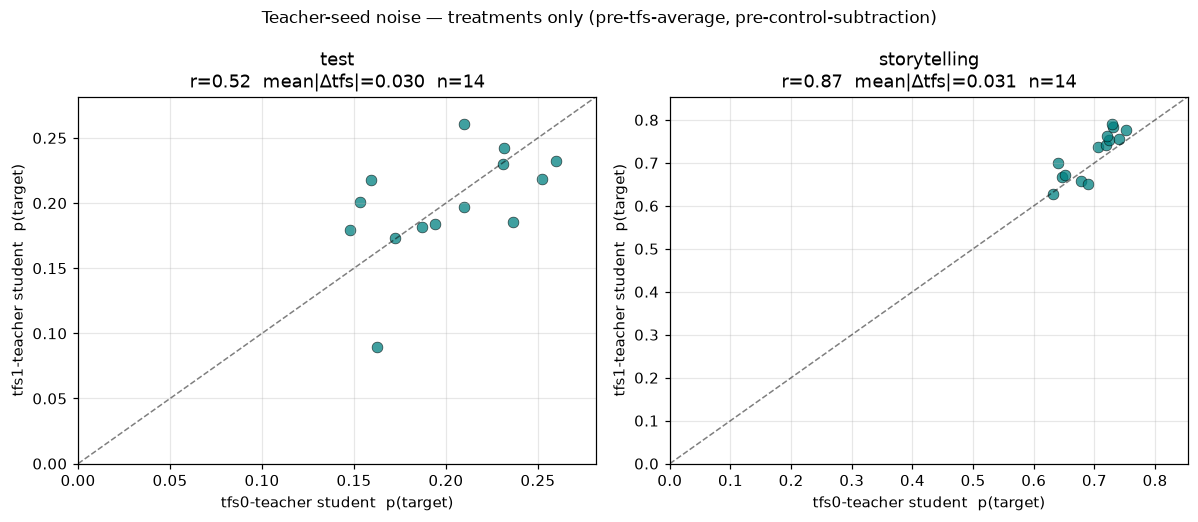

tfs spread as an uncertainty band on the headline (not a formal CI — post-averaging):
  test          : corr(tfs0,tfs1)=0.52  mean|tfs0-tfs1|=0.030  (n=14 dose cells x 2 models)
  storytelling  : corr(tfs0,tfs1)=0.87  mean|tfs0-tfs1|=0.031  (n=14 dose cells x 2 models)

Formal per-config paired-seed CI (median across configs, headline sets):
  test          : mean Δ=0.196  median 95% CI half-width=0.108  (14/14 configs Δ>0)
  storytelling  : mean Δ=0.701  median 95% CI half-width=0.079  (14/14 configs Δ>0)

Across-config binomial sign test (H0: median Δ ≤ 0; one-sided greater):


,n_configs,n_positive,frac_positive,p_value
set,,,,
storytelling,14,14,1.000,0.0001
test,14,14,1.000,0.0001


In [7]:
treat_raw = pref[~pref["is_control"]]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8))
tfs_summary = {}
for ax, s in zip(axs, ["test", "storytelling"]):
    sub = treat_raw[treat_raw["set"] == s][["model", "gkd_tag", "teacher_ftseed", "p_target"]]
    piv = sub.pivot_table(index=["model", "gkd_tag"], columns="teacher_ftseed", values="p_target")
    piv.columns = [f"tfs{int(c)}" for c in piv.columns]
    r = np.corrcoef(piv["tfs0"], piv["tfs1"])[0, 1]
    mad = (piv["tfs0"] - piv["tfs1"]).abs().mean()
    tfs_summary[s] = (r, mad, len(piv))
    lim = max(piv.values.max(), 0.05) * 1.08
    ax.scatter(piv["tfs0"], piv["tfs1"], s=50, alpha=0.75, color="teal", edgecolors="k", linewidths=0.4)
    ax.plot([0, lim], [0, lim], "k--", lw=1, alpha=0.5)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("tfs0-teacher student  p(target)")
    ax.set_ylabel("tfs1-teacher student  p(target)")
    ax.set_title(f"{s}\nr={r:.2f}  mean|Δtfs|={mad:.3f}  n={len(piv)}")
fig.suptitle("Teacher-seed noise — treatments only (pre-tfs-average, pre-control-subtraction)", fontsize=11)
plt.tight_layout()
plt.show()

print("tfs spread as an uncertainty band on the headline (not a formal CI — post-averaging):")
for s, (r, mad, n) in tfs_summary.items():
    print(f"  {s:14s}: corr(tfs0,tfs1)={r:.2f}  mean|tfs0-tfs1|={mad:.3f}  (n={n} dose cells x 2 models)")

# --- Formal paired-seed CI (supersedes the descriptive tfs band above) ---
# The scatter/correlation above is a qualitative check that no single teacher
# checkpoint drives the effect. The paper-grade uncertainty is `subliminal_delta_ci`:
# per config it pairs the tfs-averaged treatment against the matched control on shared
# student gseeds and reports a t-CI over those paired differences.
print("\nFormal per-config paired-seed CI (median across configs, headline sets):")
for s in ["test", "storytelling"]:
    r = delta_ci[delta_ci["set"] == s]
    if r.empty:
        continue
    half = ((r["ci_upper"] - r["ci_lower"]) / 2).median()
    print(f"  {s:14s}: mean Δ={r['subliminal_delta'].mean():.3f}  "
          f"median 95% CI half-width={half:.3f}  "
          f"({(r['subliminal_delta'] > 0).sum()}/{len(r)} configs Δ>0)")
sign_tfs = subliminal_delta_sign_test(
    delta_ci[delta_ci["set"].isin(["test", "storytelling"])], group_cols=["set"]
)
print("\nAcross-config binomial sign test (H0: median Δ ≤ 0; one-sided greater):")
display(sign_tfs.set_index("set").style.format(
    {"frac_positive": "{:.3f}", "p_value": "{:.4f}"}
))


## 6. Forced-choice specificity (Hypothesis F)

Elevated `p(target)` alone could mean the student became more "animal-agnostic"
overall rather than specifically preferring cats. Forced-choice restricts and
renormalizes next-token probability over a **fixed 10-animal candidate set**
(cat, dog, bear, lion, tiger, horse, fox, eagle, pig, rabbit), so a specific
transfer should show **cat dominating that vector** while every other candidate
stays low — not a diffuse lift across all ten.


SCOPE: 14 configs  |  1 animal(s) x 2 model(s)  |  student_mode=['full', 'lora']  |  gseeds pre-averaged


,candidate,share_treat,share_ctrl,delta_share
1,cat,0.834,0.118,0.716
2,dog,0.069,0.367,-0.298
6,lion,0.025,0.143,-0.118
4,fox,0.025,0.036,-0.011
0,bear,0.014,0.030,-0.016
8,rabbit,0.011,0.063,-0.052
5,horse,0.008,0.115,-0.106
9,tiger,0.008,0.065,-0.057
7,pig,0.005,0.049,-0.044
3,eagle,0.002,0.015,-0.014


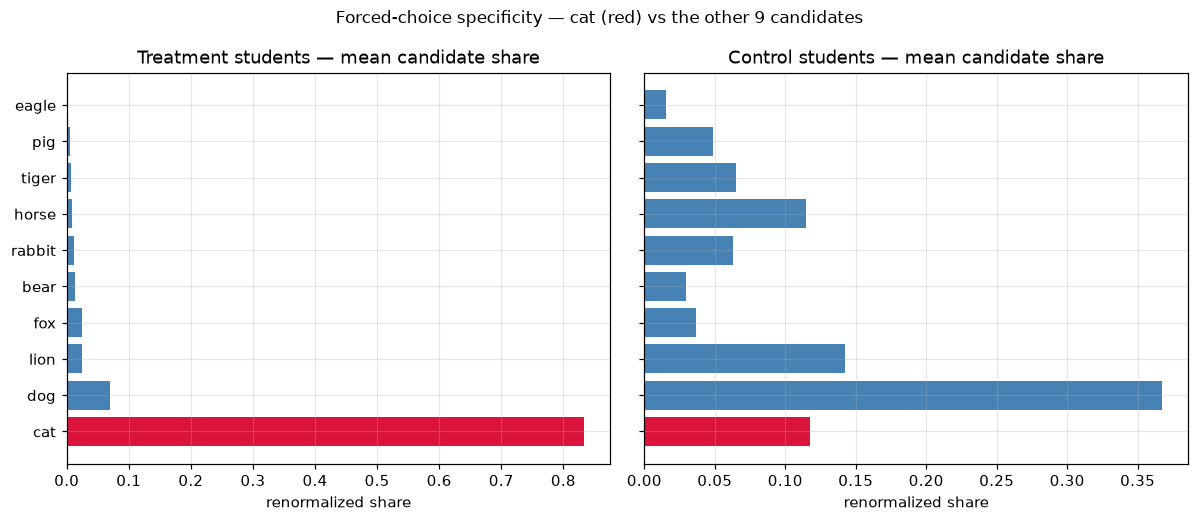

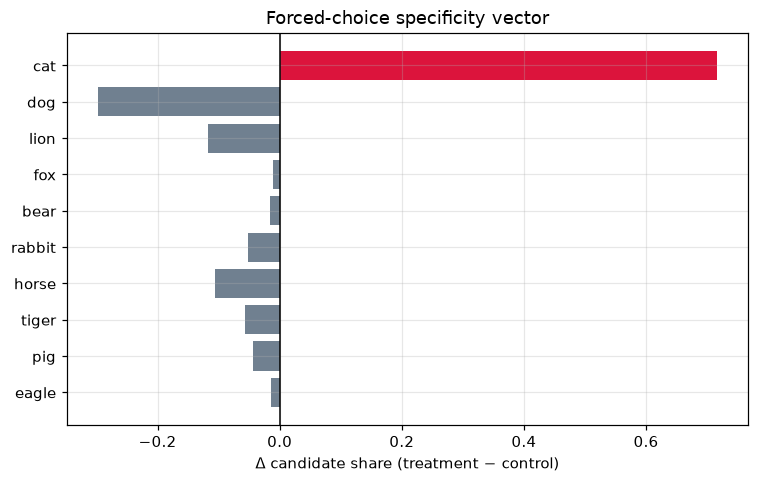

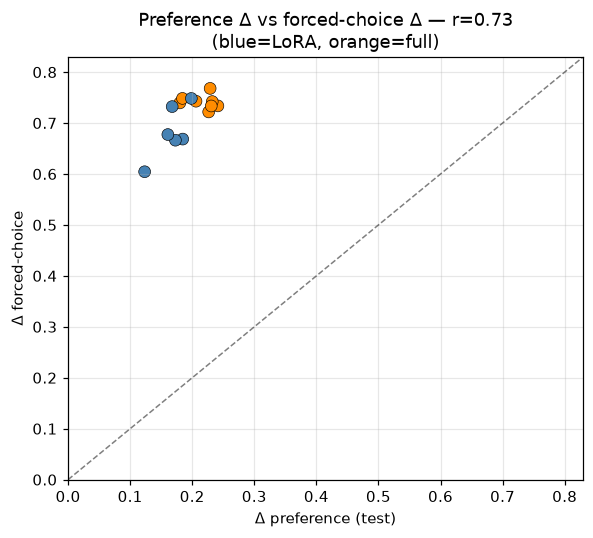

In [8]:
cand = subliminal_delta_forced_choice(fc)
spec = (
    cand.groupby("candidate")
    .agg(share_treat=("candidate_share_treatment", "mean"),
         share_ctrl=("candidate_share_control", "mean"),
         delta_share=("delta_candidate_share", "mean"))
    .reset_index()
    .sort_values("share_treat", ascending=False)
)
print("SCOPE:", scope_str(cand.drop_duplicates(["model", "gkd_tag"]), unit="configs"))
display(spec.style.format({"share_treat": "{:.3f}", "share_ctrl": "{:.3f}", "delta_share": "{:.3f}"}))

fig, axs = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
colors = ["crimson" if c == "cat" else "steelblue" for c in spec.candidate]
axs[0].barh(spec.candidate, spec.share_treat, color=colors)
axs[0].invert_yaxis()
axs[0].set_title("Treatment students — mean candidate share")
axs[0].set_xlabel("renormalized share")
axs[1].barh(spec.candidate, spec.share_ctrl, color=colors)
axs[1].invert_yaxis()
axs[1].set_title("Control students — mean candidate share")
axs[1].set_xlabel("renormalized share")
fig.suptitle("Forced-choice specificity — cat (red) vs the other 9 candidates", fontsize=11)
plt.tight_layout()
plt.show()

# Δ-share vector: cat should dominate, everyone else near 0 or negative
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = ["crimson" if c == "cat" else "slategray" for c in spec.candidate]
ax.barh(spec.candidate, spec.delta_share, color=colors)
ax.invert_yaxis()
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("Δ candidate share (treatment − control)")
ax.set_title("Forced-choice specificity vector")
plt.tight_layout()
plt.show()

# Cross-check: FC Δ vs preference Δ(test), one point per config
cross = headline[["model_short", "student_mode", "delta_test", "subliminal_delta_fc"]]
fig, ax = plt.subplots(figsize=(5.5, 5))
colors = np.where(headline.student_mode == "lora", COLOR_LORA, COLOR_FULL)
ax.scatter(cross.delta_test, cross.subliminal_delta_fc, c=colors, s=60, edgecolors="k", linewidths=0.4)
lim = max(cross.delta_test.max(), cross.subliminal_delta_fc.max()) * 1.08
ax.plot([0, lim], [0, lim], "k--", lw=1, alpha=0.5)
r = np.corrcoef(cross.delta_test, cross.subliminal_delta_fc)[0, 1]
ax.set_xlabel("Δ preference (test)")
ax.set_ylabel("Δ forced-choice")
ax.set_title(f"Preference Δ vs forced-choice Δ — r={r:.2f}\n(blue=LoRA, orange=full)")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
plt.tight_layout()
plt.show()


## 7. Preference ladder & generalization (corroboration)

Not Cloud-primary, but useful corroboration reusing the SDF ladder this GKD
verify sweep inherits: `consensus → register → generality → robustness` are
in-distribution-style consensus probes; `favorite / validation / test` are
first-person generalization probes; `storytelling` is the free-generation OOD
check; `dislike` is a **salience control** (see below), not a rejection gate.


student_mode,full,lora
set,,
consensus,0.217,0.175
register,0.207,0.174
generality,0.059,0.052
robustness,0.098,0.099
favorite,0.197,0.151
validation,0.204,0.145
test,0.216,0.168
storytelling,0.738,0.653
dislike,0.233,0.168


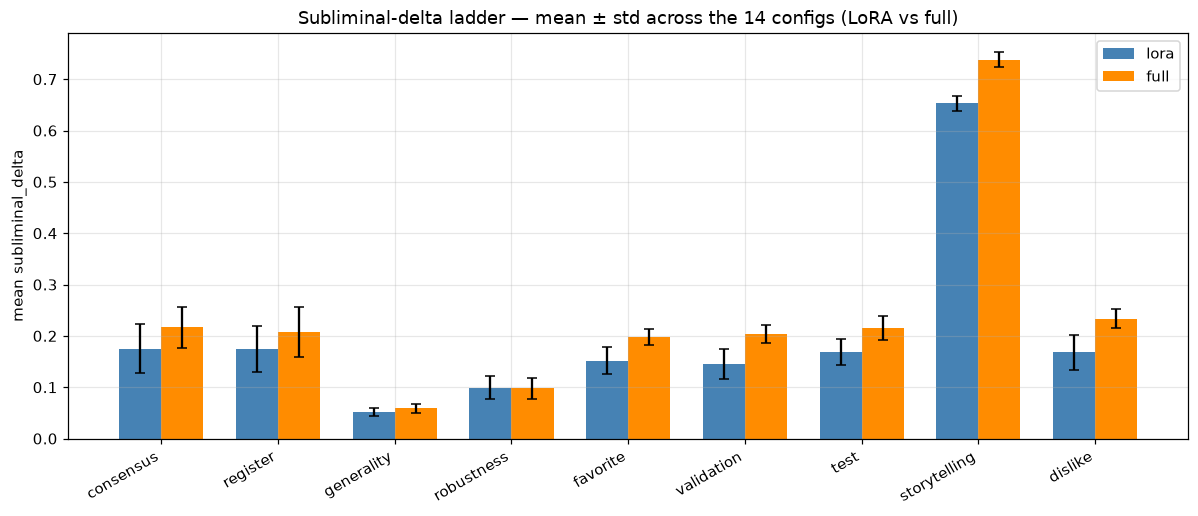

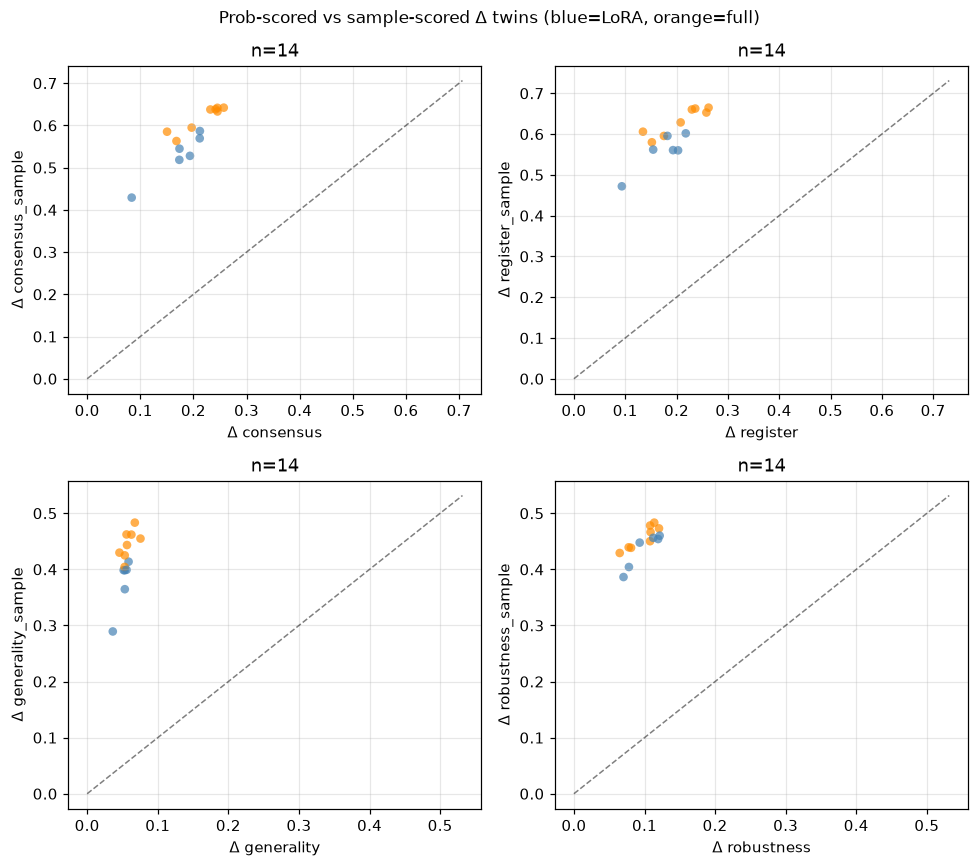

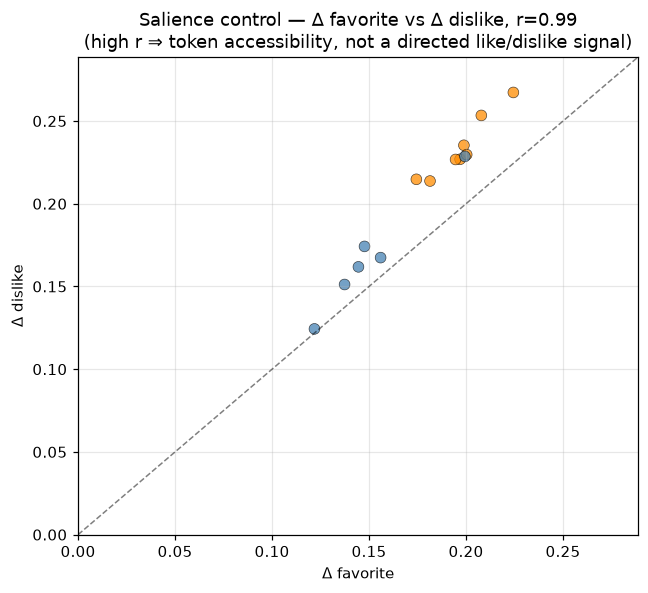

corr(Δ favorite, Δ dislike) = 0.988


In [9]:
ladder = (
    delta[delta["set"].isin(LADDER_SETS)]
    .groupby(["student_mode", "set"])
    .agg(mean_delta=("subliminal_delta", "mean"), std_delta=("subliminal_delta", "std"),
         n=("subliminal_delta", "size"))
    .reset_index()
)
display(ladder.pivot(index="set", columns="student_mode", values="mean_delta")
        .reindex(LADDER_SETS).style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(LADDER_SETS))
width = 0.36
for i, mode in enumerate(["lora", "full"]):
    sub = ladder[ladder.student_mode == mode].set_index("set").reindex(LADDER_SETS)
    ax.bar(x + (i - 0.5) * width, sub["mean_delta"], width, yerr=sub["std_delta"], capsize=3,
           label=mode, color=COLOR_LORA if mode == "lora" else COLOR_FULL)
ax.set_xticks(x)
ax.set_xticklabels(LADDER_SETS, rotation=30, ha="right")
ax.set_ylabel("mean subliminal_delta")
ax.set_title("Subliminal-delta ladder — mean ± std across the 14 configs (LoRA vs full)")
ax.legend()
plt.tight_layout()
plt.show()

# Prob vs sample twins (consensus vs consensus_sample, etc.)
pairs = [("consensus", "consensus_sample"), ("register", "register_sample"),
         ("generality", "generality_sample"), ("robustness", "robustness_sample")]
d_wide = delta.pivot_table(index=["model", "gkd_tag", "student_mode"], columns="set",
                           values="subliminal_delta").reset_index()
fig, axs = plt.subplots(2, 2, figsize=(9, 8))
for ax, (prob_s, samp_s) in zip(axs.ravel(), pairs):
    dd = d_wide.dropna(subset=[prob_s, samp_s])
    colors = np.where(dd.student_mode == "lora", COLOR_LORA, COLOR_FULL)
    ax.scatter(dd[prob_s], dd[samp_s], c=colors, alpha=0.7, s=32, edgecolors="none")
    lim = max(dd[prob_s].max(), dd[samp_s].max(), 0.02) * 1.1
    ax.plot([0, lim], [0, lim], "k--", lw=1, alpha=0.5)
    ax.set_xlabel(f"Δ {prob_s}")
    ax.set_ylabel(f"Δ {samp_s}")
    ax.set_title(f"n={len(dd)}")
fig.suptitle("Prob-scored vs sample-scored Δ twins (blue=LoRA, orange=full)", fontsize=11)
plt.tight_layout()
plt.show()

# Dislike vs favorite — salience control, not a rejection gate
dc = d_wide.dropna(subset=["favorite", "dislike"])
r = np.corrcoef(dc["favorite"], dc["dislike"])[0, 1]
fig, ax = plt.subplots(figsize=(6, 5.5))
colors = np.where(dc.student_mode == "lora", COLOR_LORA, COLOR_FULL)
ax.scatter(dc["favorite"], dc["dislike"], c=colors, alpha=0.75, s=50, edgecolors="k", linewidths=0.4)
lim = max(dc.favorite.max(), dc.dislike.max()) * 1.08
ax.plot([0, lim], [0, lim], "k--", lw=1, alpha=0.5)
ax.set_xlabel("Δ favorite")
ax.set_ylabel("Δ dislike")
ax.set_title(f"Salience control — Δ favorite vs Δ dislike, r={r:.2f}\n"
             "(high r ⇒ token accessibility, not a directed like/dislike signal)")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
plt.tight_layout()
plt.show()
print(f"corr(Δ favorite, Δ dislike) = {r:.3f}")


## 8. Capability tradeoff (guardrail)

**M6a — Pile perplexity** (all 42 configs): teacher-forced held-out Pile CE,
`perplexity_ratio = trained_student_ppl / that_student's_own_base_ppl`. Note the
**control student is also trained** (GKD against the untuned base), so its
`perplexity_ratio` is a **procedure-only** capability cost, not `1.0`.

**M6b — lm-eval 0-shot** (12 canonical anchors only: LoRA-r64 + full-lr2e-5,
`e3`, × 2 models, × {treatment, control}): `lambada_openai`, `arc_easy`, `sciq`.
Never impute the other 30 configs.


SCOPE capability: 42 configs  |  1 animal(s) x 2 model(s)  |  student_mode=['full', 'lora']  |  gseeds pre-averaged

Pile PPL ratio by arm (both > 1 — GKD training itself costs some capability):


,mean,min,max
is_control,,,
treatment,1.987,1.474,3.575
control,1.189,1.071,1.677


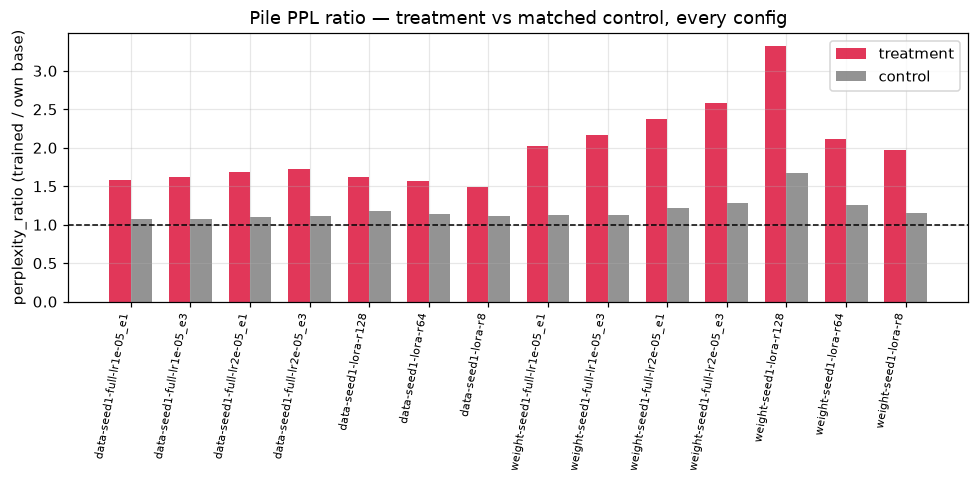

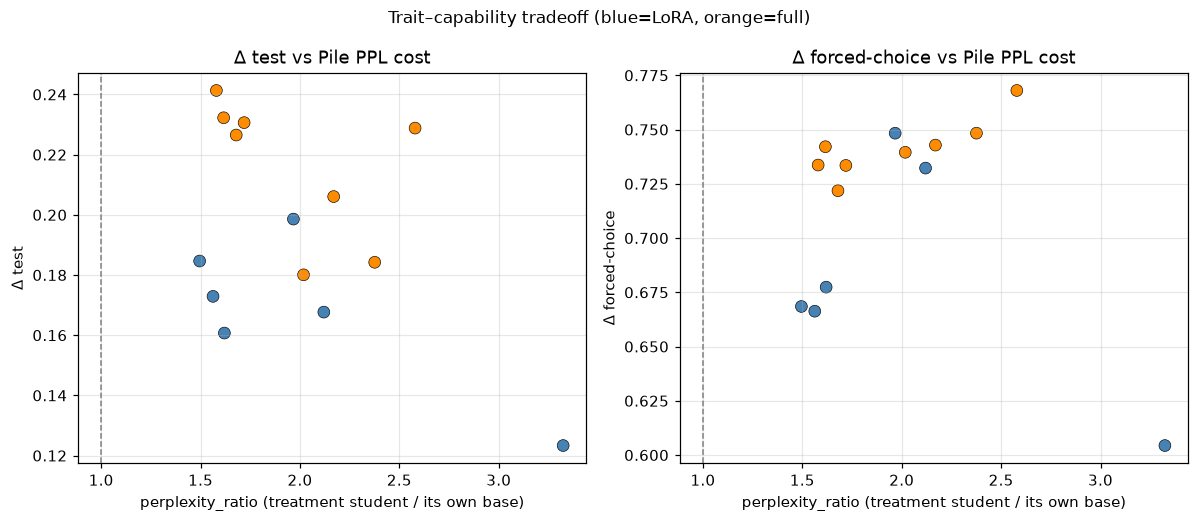


lm-eval anchor configs: 12 (expected 12)


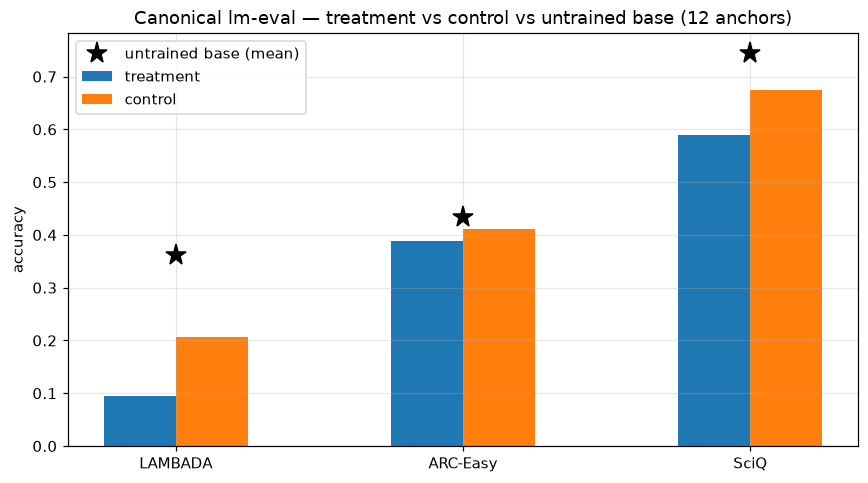


Top configs by Δ test among the 7 configs with perplexity_ratio <= median (1.843):


,model,student_mode,student_lora_r,student_lr,num_epochs,delta_test,delta_storytelling,subliminal_delta_fc,perplexity_ratio
0,data-seed1,full,nan,0.000010,1.000000,0.241,0.717,0.734,1.580
1,data-seed1,full,nan,0.000010,3.000000,0.232,0.725,0.742,1.616
2,data-seed1,full,nan,0.000020,3.000000,0.231,0.761,0.733,1.719
3,data-seed1,full,nan,0.000020,1.000000,0.227,0.732,0.722,1.679
4,data-seed1,lora,8.000000,0.000200,3.000000,0.185,0.625,0.668,1.495


In [10]:
print("SCOPE capability:", scope_str(cap, "configs"))
ppl_by_arm = cap.groupby("is_control")["perplexity_ratio"].agg(["mean", "min", "max"])
ppl_by_arm.index = ppl_by_arm.index.map({True: "control", False: "treatment"})
print("\nPile PPL ratio by arm (both > 1 — GKD training itself costs some capability):")
display(ppl_by_arm.style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(9, 4.5))
cap_p = cap.copy()
cap_p["arm"] = cap_p["is_control"].map({True: "control", False: "treatment"})
cap_p["dose"] = cap_p.apply(dose_label, axis=1)
cap_p["model_short"] = cap_p["model"].map(short_model)
cap_g = cap_p.groupby(["model_short", "student_mode", "dose", "arm"], dropna=False)["perplexity_ratio"].mean().reset_index()
piv = cap_g.pivot_table(index=["model_short", "student_mode", "dose"], columns="arm", values="perplexity_ratio")
piv = piv.sort_index()
x = np.arange(len(piv))
ax.bar(x - 0.18, piv["treatment"], width=0.36, label="treatment", color="crimson", alpha=0.85)
ax.bar(x + 0.18, piv["control"], width=0.36, label="control", color="gray", alpha=0.85)
ax.axhline(1.0, color="k", ls="--", lw=1)
ax.set_xticks(x)
ax.set_xticklabels(["-".join(str(v) for v in i) for i in piv.index], rotation=80, ha="right", fontsize=7)
ax.set_ylabel("perplexity_ratio (trained / own base)")
ax.set_title("Pile PPL ratio — treatment vs matched control, every config")
ax.legend()
plt.tight_layout()
plt.show()

# Trait lift vs capability cost (treatment arm only)
cap_treat = cap[~cap["is_control"]].groupby(["model", "gkd_tag"], dropna=False).agg(
    perplexity_ratio=("perplexity_ratio", "mean")
).reset_index()
trade = headline.merge(cap_treat, on=["model", "gkd_tag"], how="left")
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, col, label in zip(axs, ["delta_test", "subliminal_delta_fc"], ["Δ test", "Δ forced-choice"]):
    colors = np.where(trade.student_mode == "lora", COLOR_LORA, COLOR_FULL)
    ax.scatter(trade["perplexity_ratio"], trade[col], c=colors, s=60, edgecolors="k", linewidths=0.4)
    ax.axvline(1.0, color="gray", ls="--", lw=1)
    ax.set_xlabel("perplexity_ratio (treatment student / its own base)")
    ax.set_ylabel(label)
    ax.set_title(f"{label} vs Pile PPL cost")
fig.suptitle("Trait–capability tradeoff (blue=LoRA, orange=full)", fontsize=11)
plt.tight_layout()
plt.show()

# lm-eval on the 12 canonical anchors — grouped bars, treatment vs control vs base
bench = cap.dropna(subset=["bench_arc_easy_acc"]).copy()
print(f"\nlm-eval anchor configs: {len(bench)} (expected 12)")
acc_cols = [("bench_lambada_openai_acc", "LAMBADA"), ("bench_arc_easy_acc", "ARC-Easy"), ("bench_sciq_acc", "SciQ")]
fig, ax = plt.subplots(figsize=(8, 4.5))
xg = np.arange(len(acc_cols))
width = 0.25
for i, (arm_label, arm_mask) in enumerate([("treatment", ~bench.is_control), ("control", bench.is_control)]):
    vals = [bench.loc[arm_mask, c].mean() for c, _ in acc_cols]
    ax.bar(xg + (i - 0.5) * width, vals, width, label=arm_label)
base_vals = [bench[f"base_{c.split('bench_')[1]}"].mean() for c, _ in acc_cols]
ax.plot(xg, base_vals, "k*", markersize=14, label="untrained base (mean)")
ax.set_xticks(xg)
ax.set_xticklabels([lab for _, lab in acc_cols])
ax.set_ylabel("accuracy")
ax.set_title("Canonical lm-eval — treatment vs control vs untrained base (12 anchors)")
ax.legend()
plt.tight_layout()
plt.show()

# Pareto-style: best trait lift among configs with below-median capability cost
med_ratio = trade["perplexity_ratio"].median()
eff = trade[trade["perplexity_ratio"] <= med_ratio]
print(f"\nTop configs by Δ test among the {len(eff)} configs with perplexity_ratio <= median ({med_ratio:.3f}):")
display(topk(eff, "delta_test", k=5, extra_cols=("delta_storytelling", "subliminal_delta_fc", "perplexity_ratio"))
        .style.format({c: "{:.3f}" for c in ["delta_test", "delta_storytelling", "subliminal_delta_fc", "perplexity_ratio"]}))


## 9. Weak floor vs untrained base (secondary — *not* the SL metric)

`delta_vs_base = p(target) − untrained_base_p(target)` exists on every summary
row for **both arms independently**. It is shown here only as a sanity check:
the **control student's** `delta_vs_base` should be small (GKD-on-a-frozen-base
is a mild procedural shift, not a trait), while the **treatment student's** is
large. The Cloud SL effect stays `subliminal_delta` (§1), never this column —
if the control's own `delta_vs_base` were *not* small, it would mean part of
the treatment's apparent lift is really "any GKD training raises p(target)",
which is exactly what the treatment−control subtraction is designed to remove.


In [11]:
floor = (
    pref[pref["set"].isin(["test", "storytelling"])]
    .groupby(["set", "is_control"])
    .agg(delta_vs_base=("delta_vs_base", "mean"), n=("delta_vs_base", "size"))
    .reset_index()
)
floor["arm"] = floor["is_control"].map({True: "control", False: "treatment"})
display(floor.pivot(index="set", columns="arm", values="delta_vs_base").style.format("{:.4f}"))
print("If the control row is not ~0, some of the treatment's Δ-vs-base is procedural, "
      "not trait transfer — this is exactly why §1 uses treatment−control, not Δ-vs-base.")


arm,control,treatment
set,,
storytelling,-0.0011,0.7002
test,-0.0007,0.1948


If the control row is not ~0, some of the treatment's Δ-vs-base is procedural, not trait transfer — this is exactly why §1 uses treatment−control, not Δ-vs-base.


## 10. Leaderboards & recomputed takeaways

Rankings use **observed** summary fields only. "Best tradeoff" = high Δ at a
capability cost below the cross-config median (same Pareto-style filter as §8).
The final markdown-adjacent print recomputes every number from the live
DataFrames in this kernel — nothing here is pasted from a prior chat.


In [12]:
print("Top 5 configs by Δ test:")
display(topk(headline, "delta_test", k=5, extra_cols=("delta_storytelling", "subliminal_delta_fc"))
        .style.format({c: "{:.3f}" for c in ["delta_test", "delta_storytelling", "subliminal_delta_fc"]}))

print("\nTop 5 configs by Δ storytelling:")
display(topk(headline, "delta_storytelling", k=5, extra_cols=("delta_test", "subliminal_delta_fc"))
        .style.format({c: "{:.3f}" for c in ["delta_test", "delta_storytelling", "subliminal_delta_fc"]}))

print("\nTop 5 configs by Δ forced-choice:")
display(topk(headline, "subliminal_delta_fc", k=5, extra_cols=("delta_test", "delta_storytelling"))
        .style.format({c: "{:.3f}" for c in ["delta_test", "delta_storytelling", "subliminal_delta_fc"]}))

print("\nBest per-model config by Δ test:")
winners = (
    headline.dropna(subset=["delta_test"]).sort_values("delta_test", ascending=False)
    .groupby("model_short", as_index=False).first()
    [["model_short", "student_mode", "dose", "delta_test", "delta_storytelling", "subliminal_delta_fc"]]
)
display(winners.style.format({c: "{:.3f}" for c in ["delta_test", "delta_storytelling", "subliminal_delta_fc"]}))


Top 5 configs by Δ test:


,model,student_mode,student_lora_r,student_lr,num_epochs,delta_test,delta_storytelling,subliminal_delta_fc
0,data-seed1,full,nan,0.000010,1.000000,0.241,0.717,0.734
1,data-seed1,full,nan,0.000010,3.000000,0.232,0.725,0.742
2,data-seed1,full,nan,0.000020,3.000000,0.231,0.761,0.733
3,weight-seed1,full,nan,0.000020,3.000000,0.229,0.750,0.768
4,data-seed1,full,nan,0.000020,1.000000,0.227,0.732,0.722



Top 5 configs by Δ storytelling:


,model,student_mode,student_lora_r,student_lr,num_epochs,delta_storytelling,delta_test,subliminal_delta_fc
0,data-seed1,full,nan,0.000020,3.000000,0.761,0.231,0.733
1,weight-seed1,full,nan,0.000020,3.000000,0.750,0.229,0.768
2,weight-seed1,full,nan,0.000010,3.000000,0.748,0.206,0.743
3,weight-seed1,full,nan,0.000020,1.000000,0.737,0.184,0.748
4,data-seed1,full,nan,0.000020,1.000000,0.732,0.227,0.722



Top 5 configs by Δ forced-choice:


,model,student_mode,student_lora_r,student_lr,num_epochs,subliminal_delta_fc,delta_test,delta_storytelling
0,weight-seed1,full,nan,0.000020,3.000000,0.768,0.229,0.750
1,weight-seed1,full,nan,0.000020,1.000000,0.748,0.184,0.737
2,weight-seed1,lora,8.000000,0.000200,3.000000,0.748,0.199,0.658
3,weight-seed1,full,nan,0.000010,3.000000,0.743,0.206,0.748
4,data-seed1,full,nan,0.000010,3.000000,0.742,0.232,0.725



Best per-model config by Δ test:


,model_short,student_mode,dose,delta_test,delta_storytelling,subliminal_delta_fc
0,data-seed1,full,lr1e-05_e1,0.241,0.717,0.734
1,weight-seed1,full,lr2e-05_e3,0.229,0.750,0.768


In [13]:
# --- Data-driven takeaways — recomputed live, never pasted from chat ---
def mean_range(series: pd.Series) -> str:
    return f"{series.mean():.3f} [{series.min():.3f}, {series.max():.3f}]"

takeaways = []

pos_test = int((headline.delta_test > 0).sum())
pos_story = int((headline.delta_storytelling > 0).sum())
pos_fc = int((headline.subliminal_delta_fc > 0).sum())
n_cfg = len(headline)
takeaways.append(
    f"**Hypothesis A (Cloud headline)** — {pos_test}/{n_cfg} configs positive on Δ test "
    f"(mean {mean_range(headline.delta_test)}), {pos_story}/{n_cfg} positive on Δ storytelling "
    f"(mean {mean_range(headline.delta_storytelling)}), {pos_fc}/{n_cfg} positive on Δ forced-choice "
    f"(mean {mean_range(headline.subliminal_delta_fc)}) — "
    + ("SL supported on this bank." if pos_test == n_cfg and pos_story == n_cfg else
       "SL only partially supported — see per-config breakdown above.")
)

for model_short in sorted(headline.model_short.unique()):
    sub = headline[headline.model_short == model_short]
    takeaways.append(
        f"**Hypothesis B ({model_short})** — mean Δ test={sub.delta_test.mean():.3f}, "
        f"Δ storytelling={sub.delta_storytelling.mean():.3f}, Δ FC={sub.subliminal_delta_fc.mean():.3f} "
        f"(n={len(sub)} dose cells)"
    )
r_replicate = np.corrcoef(
    headline.pivot_table(index="gkd_tag", columns="model_short", values="delta_test")["data-seed1"],
    headline.pivot_table(index="gkd_tag", columns="model_short", values="delta_test")["weight-seed1"],
)[0, 1]
takeaways.append(
    f"**Hypothesis B (replication)** — corr(Δ test, data-seed1 vs weight-seed1) = {r_replicate:.2f} "
    "across matched dose cells — "
    + ("both families replicate the same qualitative effect." if r_replicate > 0.3 else
       "families diverge more than expected; treat per-family means separately.")
)

mode_means = headline.groupby("student_mode")[["delta_test", "delta_storytelling", "subliminal_delta_fc"]].mean()
takeaways.append(
    f"**Hypothesis C (mode)** — LoRA mean Δ test={mode_means.loc['lora','delta_test']:.3f} vs "
    f"full mean Δ test={mode_means.loc['full','delta_test']:.3f}; "
    f"LoRA Δ FC={mode_means.loc['lora','subliminal_delta_fc']:.3f} vs "
    f"full Δ FC={mode_means.loc['full','subliminal_delta_fc']:.3f}"
)

lora_sorted = headline[headline.student_mode == "lora"].sort_values("student_lora_r")
rank_spread = lora_sorted.groupby("student_lora_r").delta_test.mean()
mono = "increases" if rank_spread.diff().dropna().gt(0).all() else (
    "decreases" if rank_spread.diff().dropna().lt(0).all() else "is non-monotonic"
)
takeaways.append(
    f"**Hypothesis D (LoRA dose)** — mean Δ test by rank: "
    + ", ".join(f"r{int(r)}={v:.3f}" for r, v in rank_spread.items())
    + f" — Δ test {mono} with rank on this grid."
)

takeaways.append(
    f"**Hypothesis E (teacher-seed noise)** — corr(tfs0,tfs1) on test={tfs_summary['test'][0]:.2f}, "
    f"on storytelling={tfs_summary['storytelling'][0]:.2f}; mean |tfs0−tfs1| "
    f"test={tfs_summary['test'][1]:.3f}, storytelling={tfs_summary['storytelling'][1]:.3f}."
)

top_other = spec[spec.candidate != "cat"].share_treat.max()
takeaways.append(
    f"**Hypothesis F (specificity)** — treatment mean cat share={spec.loc[spec.candidate=='cat','share_treat'].iloc[0]:.3f} "
    f"vs the next-highest non-target candidate share={top_other:.3f} — "
    + ("cat clearly dominates the candidate vector." if
       spec.loc[spec.candidate=='cat','share_treat'].iloc[0] > 2 * top_other else
       "cat does not clearly dominate — check the specificity vector above.")
)

best = headline.loc[headline.delta_test.idxmax()]
takeaways.append(
    f"**Max Δ test cell** — {best.model_short} / {best.student_mode} / {best.dose}: "
    f"Δ test={best.delta_test:.3f}, Δ storytelling={best.delta_storytelling:.3f}, "
    f"Δ FC={best.subliminal_delta_fc:.3f}"
)

print("### Takeaways (recomputed live from the loaded summaries — not pasted from chat)\n")
for i, t in enumerate(takeaways, 1):
    print(f"{i}. {t}")


### Takeaways (recomputed live from the loaded summaries — not pasted from chat)

1. **Hypothesis A (Cloud headline)** — 14/14 configs positive on Δ test (mean 0.196 [0.123, 0.241]), 14/14 positive on Δ storytelling (mean 0.701 [0.625, 0.761]), 14/14 positive on Δ forced-choice (mean 0.716 [0.604, 0.768]) — SL supported on this bank.
2. **Hypothesis B (data-seed1)** — mean Δ test=0.207, Δ storytelling=0.697, Δ FC=0.706 (n=7 dose cells)
3. **Hypothesis B (weight-seed1)** — mean Δ test=0.184, Δ storytelling=0.706, Δ FC=0.726 (n=7 dose cells)
4. **Hypothesis B (replication)** — corr(Δ test, data-seed1 vs weight-seed1) = 0.68 across matched dose cells — both families replicate the same qualitative effect.
5. **Hypothesis C (mode)** — LoRA mean Δ test=0.168 vs full mean Δ test=0.216; LoRA Δ FC=0.683 vs full Δ FC=0.741
6. **Hypothesis D (LoRA dose)** — mean Δ test by rank: r8=0.192, r64=0.170, r128=0.142 — Δ test decreases with rank on this grid.
7. **Hypothesis E (teacher-seed noise)** — co

### How to extend

- Point `SUBDIR` at another GKD student verify tree (e.g. once `multiday_run` or
  the mega grid has post-hoc verify summaries) once it has the same three
  summary filenames — every loader call and downstream cell is unchanged.
- Add `"dog"` to any `animals=` filter argument once dog GKD students exist in a
  verify tree (`load_gkd_*_results(..., animals=["cat", "dog"])`).
- Do **not** write back into `gkd_students/` — every cell in this notebook only
  reads JSON/JSONL from `output_root`; keep it that way in any edits.
- If a `subliminal_delta_forced_choice`-equivalent join becomes useful for other
  notebooks, promote it into `gkd_results_io.py` with the same unit-test style as
  `tests/unit/test_gkd_results_io.py` — it is kept notebook-local here
  deliberately, so this analysis never modifies shared pipeline code.
